In [1]:
import os
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aeon.datasets import load_from_ts_file

In [2]:
# Configuration paths
data_root_path = "../datasets/"


In [5]:
results_file = "processed_sqrt.csv"
df = pd.read_csv(results_file)

name_col = (
    "Unnamed: 0"
    if "Unnamed: 0" in df.columns
    else (df.columns[0] if "class_name" not in df.columns else "class_name")
)

# Sort by accuracy ascending to get the 5 least strong ones
lowest_5 = df.sort_values(by="acc", ascending=True).head(5)

print("5 Least Strong Datasets (Lowest Accuracy)")
print(lowest_5[[name_col, "acc", "bal_acc","log_loss","auroc"]])

5 Least Strong Datasets (Lowest Accuracy)
           Unnamed: 0       acc   bal_acc  log_loss     auroc
71  PigAirwayPressure  0.340865  0.340865  2.282594  0.945920
70            Phoneme  0.377954  0.213646  3.369585  0.829579
45            Haptics  0.507035  0.506184  1.285735  0.795493
73             PigCVP  0.575801  0.575801  2.354886  0.965828
48        InlineSkate  0.586000  0.604030  1.152941  0.903156


In [6]:
results_file = "processed_scale_aware.csv"
df = pd.read_csv(results_file)
name_col = (
    "Unnamed: 0"
    if "Unnamed: 0" in df.columns
    else (df.columns[0] if "class_name" not in df.columns else "class_name")
)

# Sort by accuracy ascending to get the 5 least strong ones
lowest_5 = df.sort_values(by="acc", ascending=True).head(5)

print("5 Least Strong Datasets (Lowest Accuracy)")
print(lowest_5[[name_col, "acc", "bal_acc","log_loss","auroc"]])

5 Least Strong Datasets (Lowest Accuracy)
           Unnamed: 0       acc   bal_acc  log_loss     auroc
70            Phoneme  0.368653  0.226676  3.639494  0.825660
71  PigAirwayPressure  0.497596  0.497596  1.683676  0.973526
45            Haptics  0.519372  0.518435  1.259004  0.804169
48        InlineSkate  0.574909  0.591982  1.208595  0.895299
61    MiddlePhalanxTW  0.587879  0.411334  1.019384  0.800284


In [97]:
dataset_names_to_plot = lowest_5[name_col].tolist()

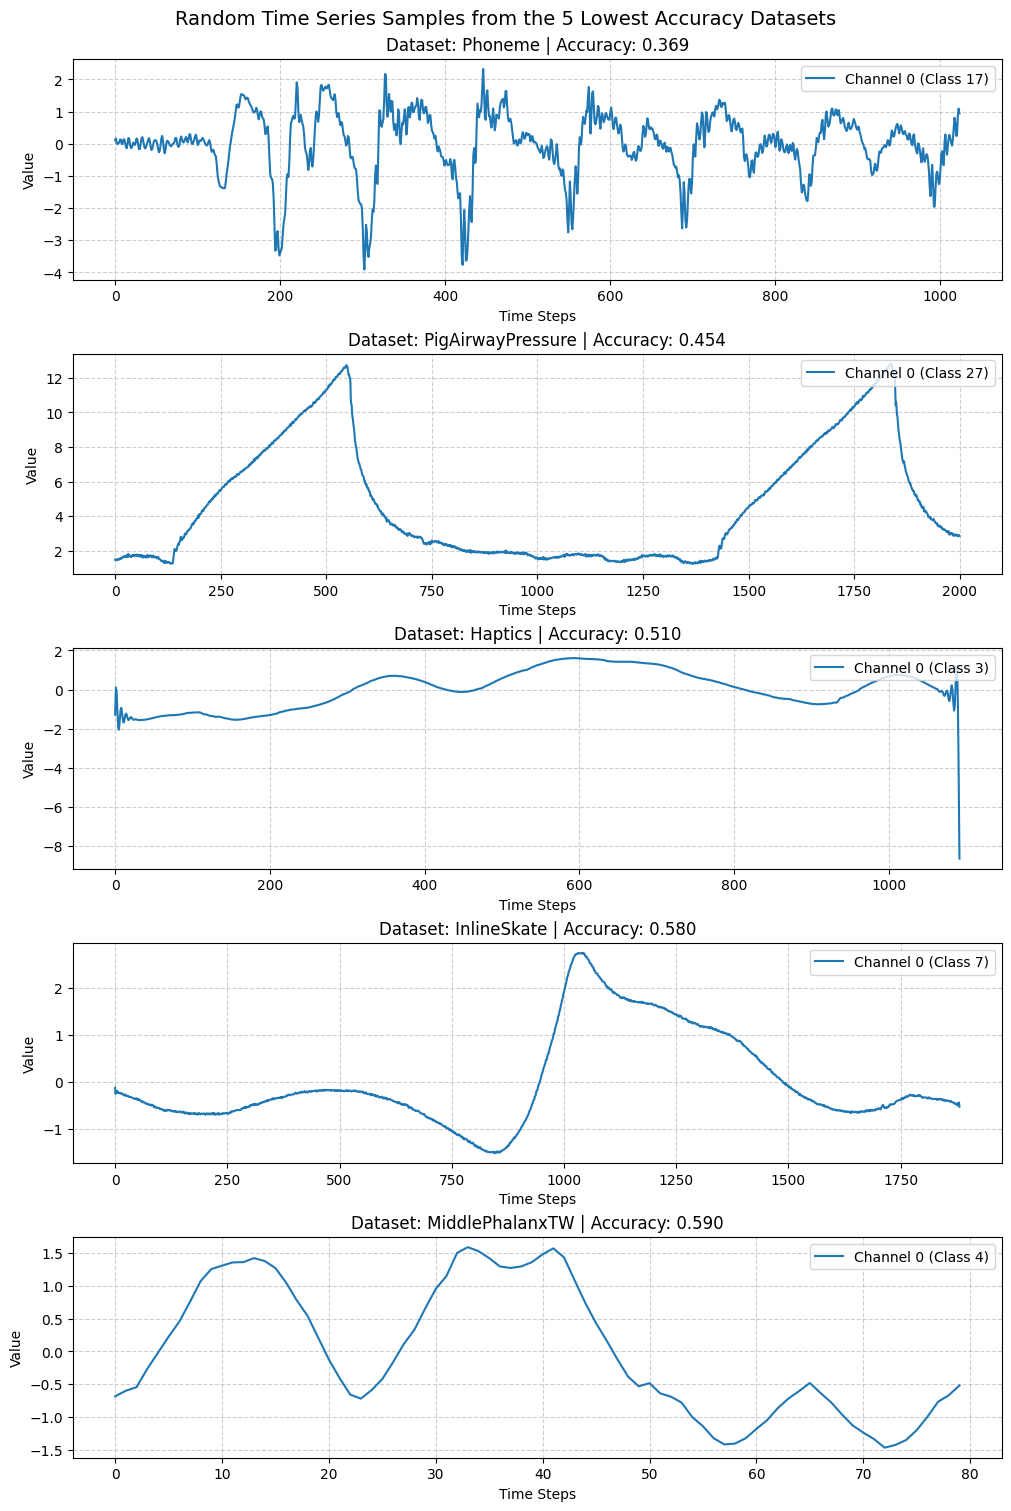

In [103]:
# Loop through the 5 datasets, load data, and plot a random series
fig, axes = plt.subplots(
    nrows=5, ncols=1, figsize=(10, 15), constrained_layout=True
)

for idx, dataset_name in enumerate(dataset_names_to_plot):
  dataset_dir = os.path.join(data_root_path, dataset_name)
  X_data = None

  if os.path.exists(dataset_dir):
    train_path = os.path.join(dataset_dir, f"{dataset_name}_TRAIN.ts")
    if not os.path.exists(train_path):
      train_path = os.path.join(dataset_dir, f"{dataset_name}0_TRAIN.ts")

    if os.path.exists(train_path):
      X_data, y_data = load_from_ts_file(train_path)
    else:
      print(f"Could not find .ts train file for {dataset_name}")
  else:
    print(f"Directory not found for {dataset_name}")

  ax = axes[idx] if len(dataset_names_to_plot) > 1 else axes

  if X_data is not None and len(X_data) > 0:
    # Pick a random sample index
    rand_sample_idx = random.randint(0, len(X_data) - 1)
    sample_series = X_data[rand_sample_idx]

    # Handle univariate vs multivariate shape: (channels, length) or (length,)
    if sample_series.ndim > 1:
      # Plot each channel if multivariate
      for c in range(sample_series.shape[0]):
        ax.plot(
            sample_series[c],
            label=f"Channel {c} (Class {y_data[rand_sample_idx]})",
        )
      ax.legend(loc="upper right")
    else:
      ax.plot(
          sample_series,
          color="tab:red",
          label=f"Class: {y_data[rand_sample_idx]}",
      )
      ax.legend(loc="upper right")

    # Get accuracy from dataframe for title
    acc_val = lowest_5.loc[lowest_5[name_col] == dataset_name, "acc"].values[0]
    ax.set_title(f"Dataset: {dataset_name} | Accuracy: {acc_val:.3f}")
    ax.set_xlabel("Time Steps")
    ax.set_ylabel("Value")
    ax.grid(True, linestyle="--", alpha=0.6)
  else:
    ax.text(
        0.5,
        0.5,
        f"Data missing for {dataset_name}",
        horizontalalignment="center",
        verticalalignment="center",
        transform=ax.transAxes,
    )

plt.suptitle(
    "Random Time Series Samples from the 5 Lowest Accuracy Datasets",
    fontsize=14,
)
plt.show()